In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score, mean_squared_error
from sklearn.datasets import make_moons, make_classification
SEED = 42
df = pd.read_csv(Path('data') / 'Orange_Telecom_Churn_Data.csv')
assert not df.isna().any().any()
X = df.drop(columns=['state', 'area_code', 'phone_number', 'churned']).copy()
for col in ['intl_plan', 'voice_mail_plan']:
    X[col] = X[col].map({'no': 0, 'yes': 1})
y = df['churned'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
def pipeline(k=3, weights='uniform', p=2):
    return Pipeline([('scale', MinMaxScaler()), ('knn', KNeighborsClassifier(n_neighbors=k, weights=weights, p=p))])
print('Dimensiuni:', df.shape, '| Train:', X_train.shape, '| Test:', X_test.shape)
display(y.value_counts().rename(index={0:'Nu renunță',1:'Renunță'}))


Dimensiuni: (5000, 21) | Train: (4000, 17) | Test: (1000, 17)
churned
Nu renunță    4293
Renunță        707
Name: count, dtype: int64


## 1. Import și caracteristici

In [2]:
display(df.head().T)
print(df.dtypes)
print('Caracteristici păstrate:',list(X.columns))

,0,1,2,3,4
state,KS,OH,NJ,OH,OK
account_length,128,107,137,84,75
area_code,415,415,415,408,415
phone_number,382-4657,371-7191,358-1921,375-9999,330-6626
intl_plan,no,no,no,yes,yes
voice_mail_plan,yes,yes,no,no,no
number_vmail_messages,25,26,0,0,0
total_day_minutes,265.1,161.6,243.4,299.4,166.7
total_day_calls,110,123,114,71,113
total_day_charge,45.07,27.47,41.38,50.9,28.34


state                                str
account_length                     int64
area_code                          int64
phone_number                         str
intl_plan                            str
voice_mail_plan                      str
number_vmail_messages              int64
total_day_minutes                float64
total_day_calls                    int64
total_day_charge                 float64
total_eve_minutes                float64
total_eve_calls                    int64
total_eve_charge                 float64
total_night_minutes              float64
total_night_calls                  int64
total_night_charge               float64
total_intl_minutes               float64
total_intl_calls                   int64
total_intl_charge                float64
number_customer_service_calls      int64
churned                             bool
dtype: object
Caracteristici păstrate: ['account_length', 'intl_plan', 'voice_mail_plan', 'number_vmail_messages', 'total_day_minutes', 'to

Numărul de telefon este identificator. State și area_code sunt eliminate conform cerinței; utilitatea lor predictivă ar trebui verificată prin validare.

## 2. Codificare și scalare

In [3]:
display(X.head())
sc_all=MinMaxScaler()
X_data=sc_all.fit_transform(X)
y_data=y.to_numpy()
print('Interval:',X_data.min(),X_data.max())

,account_length,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls
0,128,0,1,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1
1,107,0,1,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1
2,137,0,0,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0
3,84,1,0,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2
4,75,1,0,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3


Interval: 0.0 1.0


Planurile sunt codificate no=0, yes=1; ținta False=0, True=1. Scalarea pe întregul set este utilizată aici numai pentru demonstrația cerută de evaluare pe train. Evaluarea corectă este implementată în notebook-ul principal.

## 3. Model K=3

In [4]:
knn=KNeighborsClassifier(n_neighbors=3).fit(X_data,y_data)
y_pred=knn.predict(X_data)

Modelul este evaluat pe aceleași observații pe care le memorează.

## 4. Acuratețe

In [5]:
def accuracy(real,predict):
    real,predict=np.asarray(real),np.asarray(predict)
    if real.shape != predict.shape or real.size==0: raise ValueError('Etichete incompatibile')
    return float(np.mean(real==predict))
print('Accuracy train:',accuracy(y_data,y_pred))
assert accuracy([0,1],[1,1])==.5

Accuracy train: 0.9422


Funcția folosește argumentele primite, corectând referințele greșite la variabile globale din fișierul inițial.

## 5. Ponderi și Manhattan

In [6]:
for w,p in [('distance',2),('uniform',1)]:
    model=KNeighborsClassifier(3,weights=w,p=p).fit(X_data,y_data)
    print(w,'p=',p,'accuracy train=',accuracy(y_data,model.predict(X_data)))

distance p= 2 accuracy train= 1.0
uniform p= 1 accuracy train= 0.9456


Punctul $x_i$ este propriul vecin, la distanța zero. La K=1, eticheta sa este reprodusă. Cu weights='distance', scikit-learn acordă voturile vecinilor la distanță zero, excluzând vecinii cu distanță pozitivă din votul respectiv. Astfel apare frecvent acuratețea 1 pe train, inclusiv la K=3. Duplicatele identice cu etichete contradictorii pot împiedica 100%. K=3 cu vot uniform nu garantează 100%. Scorul pe train nu estimează generalizarea; chiar 100% pe train nu dovedește singur cât de mare este supraantrenarea. Parametrii au fost corectați conform enunțului: K=3 și p=1 pentru Manhattan.

## 6. K între 1 și 20

,k,accuracy_train
0,1,1.0000
1,2,0.9292
2,3,0.9422
3,4,0.9154
4,5,0.9284
5,6,0.9156
6,7,0.9254
7,8,0.9122
8,9,0.9224
9,10,0.9092


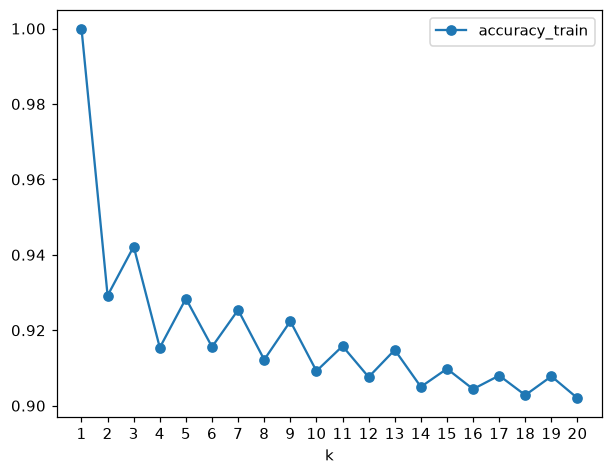

In [7]:
scores=[]
for k in range(1,21):
    model=KNeighborsClassifier(k,p=2).fit(X_data,y_data)
    scores.append((k,accuracy(y_data,model.predict(X_data))))
score_df=pd.DataFrame(scores,columns=['k','accuracy_train'])
display(score_df)
score_df.plot(x='k',y='accuracy_train',marker='o',xticks=range(1,21)); plt.show()

K=1 reproduce etichetele de train, în absența duplicatelor contradictorii. Graficul de train nu stabilește K optim pentru generalizare; folosim CV în exercițiul 7 al laboratorului principal.